# Homework 2: Machine Learning for Regression

ML Zoomcamp 2026 — predicting car fuel efficiency (`fuel_efficiency_mpg`) with linear regression implemented in NumPy.

In [1]:
import numpy as np
import pandas as pd

## Dataset

In [2]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
df = pd.read_csv(url)

columns = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']
df = df[columns]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


## EDA

Does `fuel_efficiency_mpg` have a long tail?

In [3]:
df.fuel_efficiency_mpg.describe()

count    10000.000000
mean        29.997700
std          2.930245
min         19.800000
25%         28.000000
50%         30.000000
75%         31.900000
max         41.200000
Name: fuel_efficiency_mpg, dtype: float64

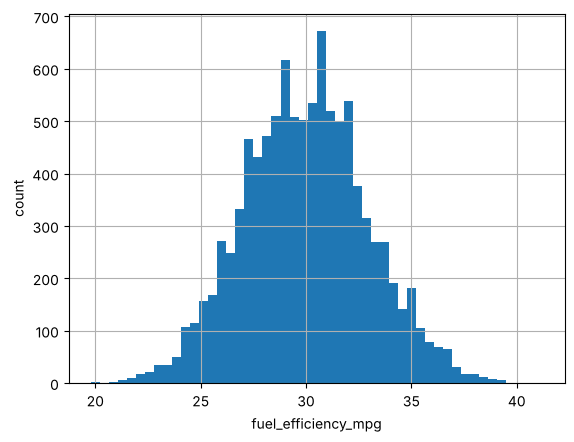

In [4]:
import matplotlib.pyplot as plt

df.fuel_efficiency_mpg.hist(bins=50)
plt.xlabel('fuel_efficiency_mpg')
plt.ylabel('count')
plt.show()

Mean and median are both about 30 and the distribution is roughly symmetric, so there is no long tail.

## Question 1. Missing values

In [5]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

**Answer:** `horsepower`

## Question 2. Median for horsepower

In [6]:
df.horsepower.median()

np.float64(254.0)

**Answer:** 254

## Prepare and split the dataset

In [7]:
def split(df, seed):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
    df_val = df.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
    df_test = df.iloc[idx[n_train + n_val:]].reset_index(drop=True)
    return df_train, df_val, df_test


features = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']
target = 'fuel_efficiency_mpg'


def prepare_X(df, fill_value):
    return df[features].fillna(fill_value).values


def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])
    w_full = np.linalg.inv(XTX).dot(X.T).dot(y)
    return w_full[0], w_full[1:]


def rmse(y, y_pred):
    return np.sqrt(((y - y_pred) ** 2).mean())

In [8]:
df_train, df_val, df_test = split(df, 42)
y_train = df_train[target].values
y_val = df_val[target].values
len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

## Question 3. Filling NAs

In [9]:
# Option 1: fill with 0
X_train = prepare_X(df_train, 0)
w0, w = train_linear_regression_reg(X_train, y_train)
score_zero = rmse(y_val, w0 + prepare_X(df_val, 0).dot(w))

# Option 2: fill with the mean computed on the training set only
hp_mean = df_train.horsepower.mean()
X_train = prepare_X(df_train, hp_mean)
w0, w = train_linear_regression_reg(X_train, y_train)
score_mean = rmse(y_val, w0 + prepare_X(df_val, hp_mean).dot(w))

round(score_zero, 3), round(score_mean, 3)

(np.float64(2.205), np.float64(2.202))

**Answer:** With mean

## Question 4. Best regularization

In [10]:
X_train = prepare_X(df_train, 0)
X_val = prepare_X(df_val, 0)

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    score = rmse(y_val, w0 + X_val.dot(w))
    print(r, round(score, 4))

0 2.2053
0.01 2.2058
0.1 2.2241
1 2.3492
5 2.4094
10 2.4195
100 2.4292


**Answer:** 0

## Question 5. RMSE standard deviation

In [11]:
scores = []
for seed in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    df_train, df_val, df_test = split(df, seed)
    w0, w = train_linear_regression_reg(prepare_X(df_train, 0), df_train[target].values)
    score = rmse(df_val[target].values, w0 + prepare_X(df_val, 0).dot(w))
    scores.append(score)
    print(seed, round(score, 4))

round(np.std(scores), 3)

0 2.2392
1 2.2021
2 2.1634
3 2.2044
4 2.2019
5 2.2458
6 2.2697
7 2.1908
8 2.2166
9 2.207


np.float64(0.029)

**Answer:** 0.029

## Question 6. Evaluation on test

In [12]:
df_train, df_val, df_test = split(df, 9)
df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)

w0, w = train_linear_regression_reg(prepare_X(df_full_train, 0), df_full_train[target].values, r=0.001)
score = rmse(df_test[target].values, w0 + prepare_X(df_test, 0).dot(w))
round(score, 3)

np.float64(2.236)

**Answer:** 2.236